## Arbol de Decision

Dimensiones: (569, 30)

Primeros registros:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  wo

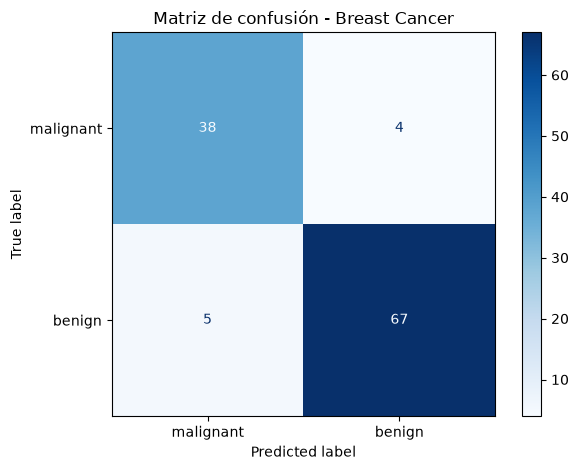

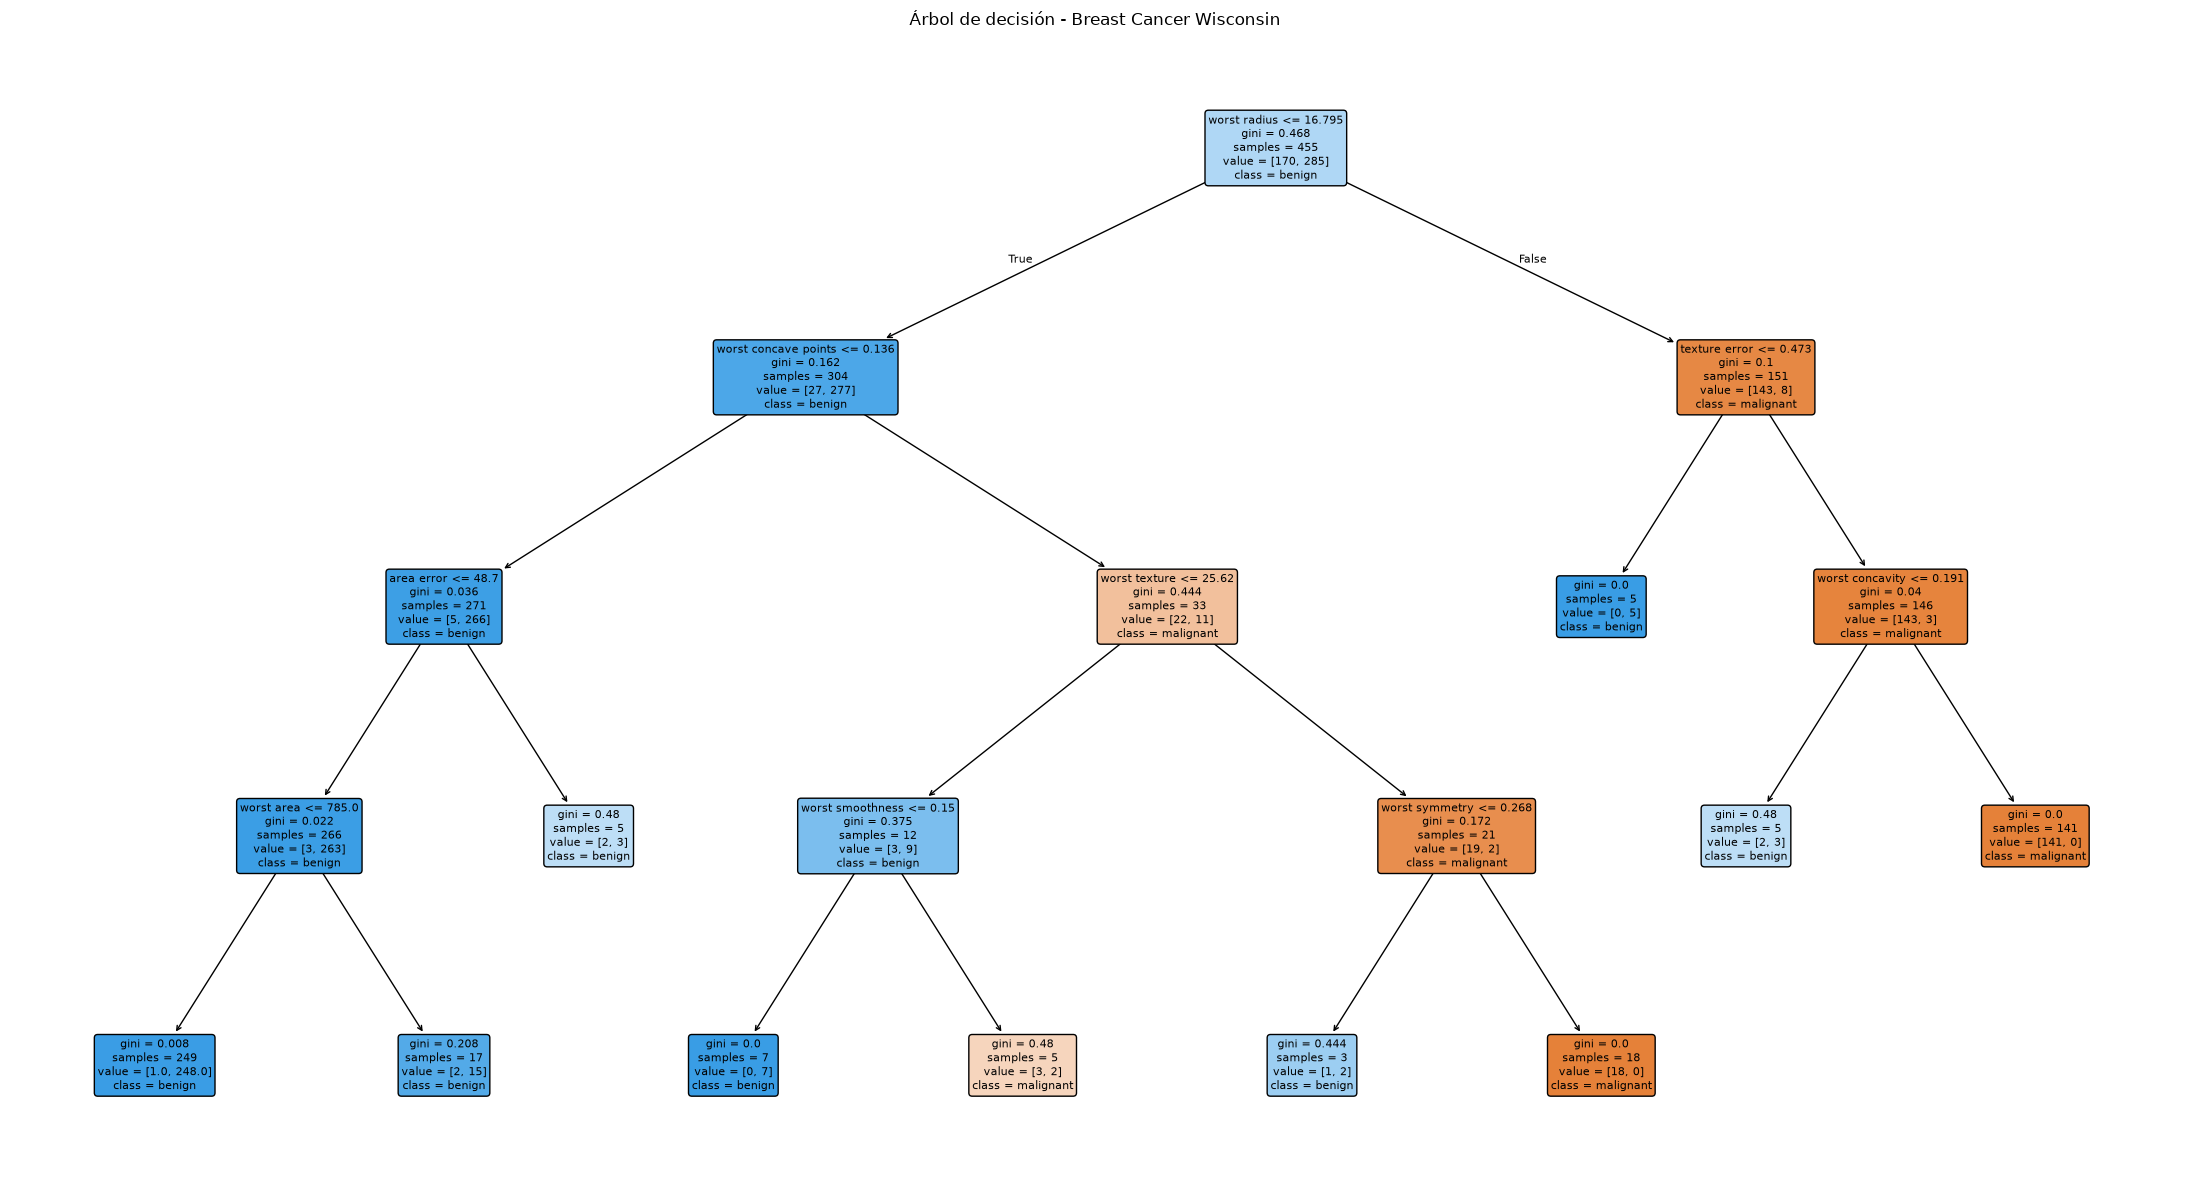


--- Reglas del árbol ---
|--- worst radius <= 16.80
|   |--- worst concave points <= 0.14
|   |   |--- area error <= 48.70
|   |   |   |--- worst area <= 785.00
|   |   |   |   |--- class: 1
|   |   |   |--- worst area >  785.00
|   |   |   |   |--- class: 1
|   |   |--- area error >  48.70
|   |   |   |--- class: 1
|   |--- worst concave points >  0.14
|   |   |--- worst texture <= 25.62
|   |   |   |--- worst smoothness <= 0.15
|   |   |   |   |--- class: 1
|   |   |   |--- worst smoothness >  0.15
|   |   |   |   |--- class: 0
|   |   |--- worst texture >  25.62
|   |   |   |--- worst symmetry <= 0.27
|   |   |   |   |--- class: 1
|   |   |   |--- worst symmetry >  0.27
|   |   |   |   |--- class: 0
|--- worst radius >  16.80
|   |--- texture error <= 0.47
|   |   |--- class: 1
|   |--- texture error >  0.47
|   |   |--- worst concavity <= 0.19
|   |   |   |--- class: 1
|   |   |--- worst concavity >  0.19
|   |   |   |--- class: 0


--- Predicción de ejemplo ---
Clase estimada: ma

In [3]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import (
    DecisionTreeClassifier,
    plot_tree,
    export_text
)
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix
)

# --------------------------------------------------
# 1. Cargar el dataset
# --------------------------------------------------

dataset = load_breast_cancer()

X = pd.DataFrame(
    dataset.data,
    columns=dataset.feature_names
)

# En el dataset original:
# 0 = malignant
# 1 = benign
y = dataset.target

print("Dimensiones:", X.shape)
print("\nPrimeros registros:")
print(X.head())

print("\nClases:")
print(dataset.target_names)

print("\nDistribución de clases:")
print(pd.Series(y).map(
    {0: "malignant", 1: "benign"}
).value_counts())


# --------------------------------------------------
# 2. Separar entrenamiento y prueba
# --------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nRegistros de entrenamiento:", len(X_train))
print("Registros de prueba:", len(X_test))


# --------------------------------------------------
# 3. Crear el árbol de decisión
# --------------------------------------------------

modelo = DecisionTreeClassifier(
    criterion="gini",
    max_depth=4,
    min_samples_leaf=3,
    random_state=42
)


# --------------------------------------------------
# 4. Entrenar
# --------------------------------------------------

modelo.fit(X_train, y_train)


# --------------------------------------------------
# 5. Predecir
# --------------------------------------------------

y_pred = modelo.predict(X_test)


# --------------------------------------------------
# 6. Evaluar el modelo
# --------------------------------------------------

accuracy = accuracy_score(y_test, y_pred)

print("\n--- Evaluación del modelo ---")
print(f"Accuracy: {accuracy:.4f}")

print("\nReporte de clasificación:")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=dataset.target_names,
        zero_division=0
    )
)

print("\nMatriz de confusión:")
print(confusion_matrix(y_test, y_pred))


# --------------------------------------------------
# 7. Visualizar matriz de confusión
# --------------------------------------------------

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=dataset.target_names,
    cmap="Blues"
)

plt.title("Matriz de confusión - Breast Cancer")
plt.tight_layout()
plt.show()


# --------------------------------------------------
# 8. Visualizar el árbol
# --------------------------------------------------

plt.figure(figsize=(22, 12))

plot_tree(
    modelo,
    feature_names=dataset.feature_names,
    class_names=dataset.target_names,
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Árbol de decisión - Breast Cancer Wisconsin")
plt.tight_layout()
plt.show()


# --------------------------------------------------
# 9. Mostrar reglas aprendidas
# --------------------------------------------------

reglas = export_text(
    modelo,
    feature_names=list(X.columns)
)

print("\n--- Reglas del árbol ---")
print(reglas)


# --------------------------------------------------
# 10. Predecir una nueva muestra
# --------------------------------------------------

nueva_muestra = X.iloc[[0]].copy()

prediccion = modelo.predict(nueva_muestra)[0]
probabilidades = modelo.predict_proba(nueva_muestra)[0]

print("\n--- Predicción de ejemplo ---")
print("Clase estimada:", dataset.target_names[prediccion])

print("\nProbabilidades estimadas:")

for clase, probabilidad in zip(
    dataset.target_names,
    probabilidades
):
    print(f"{clase}: {probabilidad:.2%}")
